In [1]:
import sys
import os
import pandas as pd
import scanpy as sc
from mudata import MuData
import muon as mu
import numpy as np

pd.set_option('display.max_columns', 100)
# os.chdir('/data1/liyuzhe/Ref/cpdb')

2026-03-19 10:56:49.406050: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-03-19 10:56:49.461796: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-03-19 10:56:50.323590: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


In [2]:
print(sys.version)

3.8.5 (default, Sep  4 2020, 07:30:14) 
[GCC 7.3.0]


In [3]:
# figure settings
sc.settings.set_figure_params(dpi=200, frameon=False)
sc.set_figure_params(dpi=200, facecolor="white")
sc.set_figure_params(figsize=(5, 5))

# Load data

In [4]:
mdata=mu.read('/data1/liyuzhe/data_share/brain_tumor/adata_all_rna_atac_celltype.h5mu')
metadata=pd.read_csv('/data1/liyuzhe/data_share/brain_tumor/refine_metadata.csv',index_col=0)
mdata.obs.loc[metadata.index,['major_cluster','celltype','subtype']]=metadata[['major_cluster','celltype','subtype']].copy()
mdata=mdata[~mdata.obs.celltype.isin(['Oligodendrocyte'])].copy()

In [5]:
cancer=[]
for i in mdata.obs.cancer_type:
    if i =='Circumscribed low-grade glioma (CLGG)':
        cancer.append('CLGG')
    elif i=='Diffuse high-grade glioma (DHGG)':
        cancer.append('DHGG')
    elif i=='Ependymoma (EPN)':
        cancer.append('EPN')
    elif i=='Medulloblastoma (MB)':
        cancer.append('MB')
        
mdata.obs.cancer=cancer

/home/liyuzhe/anaconda3/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


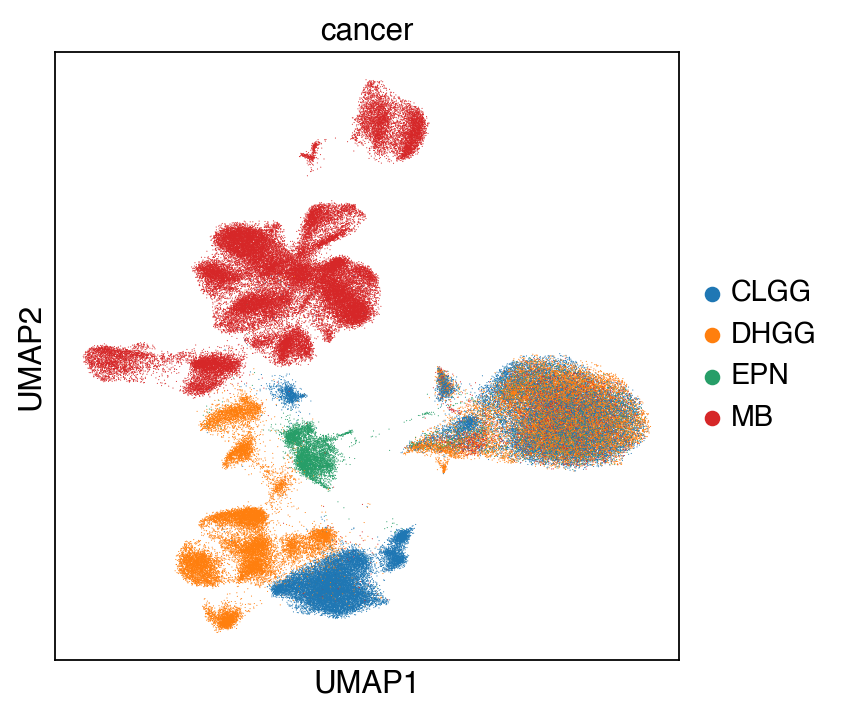

In [6]:
sc.pl.umap(mdata,color=['cancer'])

In [7]:
celltype=[]
for i in mdata.obs.index:
    if mdata.obs.loc[i,'major_cluster']=='Tumor cells':
        if mdata.obs.loc[i,'patient'] in ['MB05','MB06']:
            celltype.append('SHH')
        elif mdata.obs.loc[i,'patient'] in ['MB09','MB10','MB12']:
            celltype.append('Group4')
        elif mdata.obs.loc[i,'patient'] in ['MB01','MB02', 'MB03', 'MB04', 'MB07', 'MB08', 'MB11', 'MB13']:
            celltype.append('Group3')
        else:
            celltype.append('Other')
    else:
        celltype.append(mdata.obs.loc[i,'celltype'])

In [8]:
mdata.obs['celltype']=celltype

/home/liyuzhe/anaconda3/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


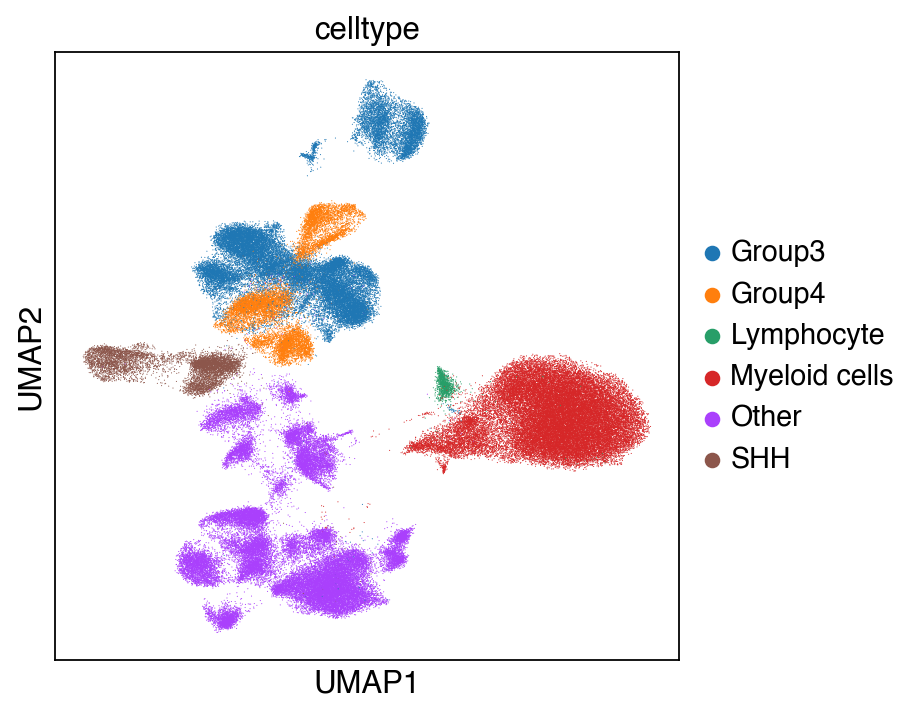

In [9]:
sc.pl.umap(mdata,color=['celltype'])

In [10]:
celltype=[]
for i in mdata.obs.index:
    if mdata.obs.loc[i,'subtype'].startswith('Microglia'):
        celltype.append(mdata.obs.loc[i,'subtype'])
    elif mdata.obs.loc[i,'subtype'].startswith('Macrophage'):
        celltype.append(mdata.obs.loc[i,'subtype'])
    else:
        celltype.append(mdata.obs.loc[i,'celltype'])
mdata.obs['celltype']=celltype

In [11]:
mdata=mdata[mdata.obs.celltype!='Other']

/home/liyuzhe/anaconda3/lib/python3.8/site-packages/anndata/_core/anndata.py:1230: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/liyuzhe/anaconda3/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


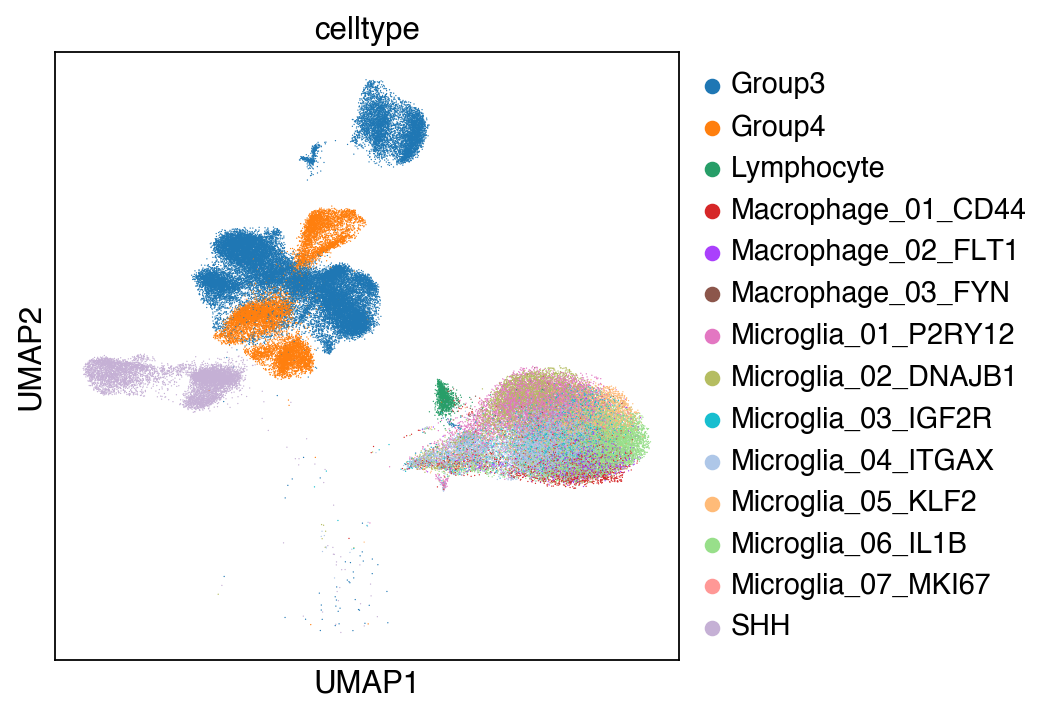

In [12]:
sc.pl.umap(mdata,color=['celltype'])

In [13]:
death=pd.read_excel('/home/zhangjinsong/tmp/Brain_tumor_meta.xlsx',sheet_name='Sheet10')
rec=pd.read_excel('/home/zhangjinsong/tmp/Brain_tumor_meta.xlsx',sheet_name='Sheet9')
pid=pd.read_excel('/home/zhangjinsong/tmp/Brain_tumor_meta.xlsx',sheet_name='Sheet2')
tmp=pd.concat([pid,death,rec],axis=1)
tmp=tmp.set_index('PatientID')

In [14]:
new_cluster_names=tmp['Death']
mdata.obs['death'] = mdata.obs.patient.map(new_cluster_names).astype(str) # astype("category")

new_cluster_names=tmp['Recurrence']
mdata.obs['recurrence'] = mdata.obs.patient.map(new_cluster_names).astype('Int64').astype(str) # astype("category")

In [15]:
mdata.obs.recurrence=mdata.obs.recurrence.replace('<NA>','nan')

/home/liyuzhe/anaconda3/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/liyuzhe/anaconda3/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


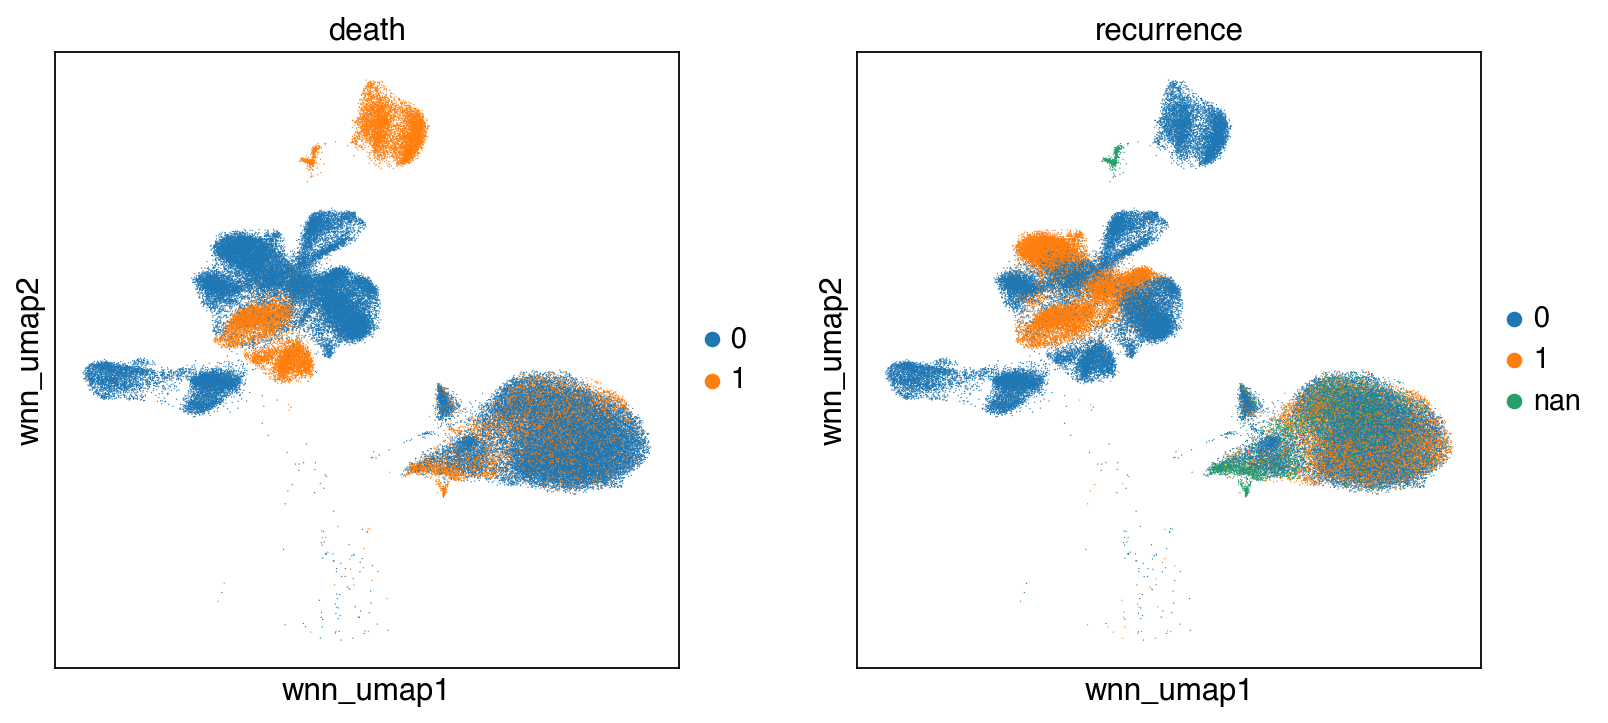

In [16]:
sc.pl.embedding(mdata,basis='wnn_umap',color=['death','recurrence'])

/home/liyuzhe/anaconda3/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


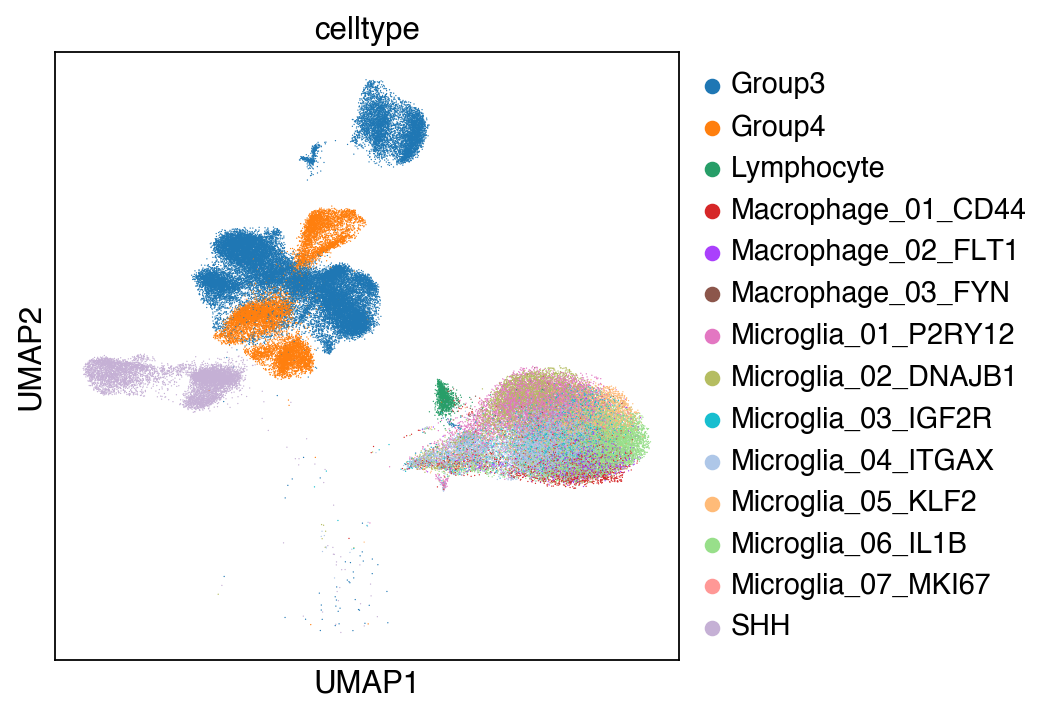

In [17]:
sc.pl.umap(mdata,color=['celltype'])

In [18]:
mdata.obs.celltype.value_counts()

celltype
Group3                 30462
Group4                 10981
Microglia_04_ITGAX      8055
Microglia_06_IL1B       7505
SHH                     6683
Microglia_01_P2RY12     6486
Microglia_02_DNAJB1     5121
Microglia_03_IGF2R      3165
Microglia_05_KLF2       2992
Macrophage_01_CD44      1979
Macrophage_02_FLT1      1566
Lymphocyte              1103
Microglia_07_MKI67       495
Macrophage_03_FYN        134
Name: count, dtype: int64

In [19]:
mdata.obs.celltype.cat.categories

Index(['Group3', 'Group4', 'Lymphocyte', 'Macrophage_01_CD44',
       'Macrophage_02_FLT1', 'Macrophage_03_FYN', 'Microglia_01_P2RY12',
       'Microglia_02_DNAJB1', 'Microglia_03_IGF2R', 'Microglia_04_ITGAX',
       'Microglia_05_KLF2', 'Microglia_06_IL1B', 'Microglia_07_MKI67', 'SHH'],
      dtype='object')

In [19]:
adata=mdata['rna']
adata=adata.raw.to_adata()
adata.obs=mdata[adata.obs.index].obs.copy()
# adata_counts=sc.read('/data1/liyuzhe/data/brain_tumor_2023/adata_all_counts.h5ad')
# Store the counts for later use
# adata.layers["counts"] = adata_counts[adata.obs.index].X.copy()

In [20]:
adata.shape

(86727, 21360)

In [21]:
metadata = adata.obs[['celltype']].copy()
metadata=metadata.reset_index()
metadata=metadata[['index','celltype']].copy()
metadata.columns=['barcode_sample','cell_type']
metadata.head(3)

,barcode_sample,cell_type
0,WYF0014.GAAGAGTAAATGCCTTCAATAG,Microglia_02_DNAJB1
1,W060505.ATGGAATGTCACCTTATGTGAGG,Microglia_05_KLF2
2,WYF0078.CCATTGTCTCGCCTCAACCACGT,Group4


In [22]:
list(adata.obs.index).sort() == list(metadata['barcode_sample']).sort()

True

In [23]:
# del adata.obs,adata.var,adata.uns,adata.obsm,adata.obsp
# adata

In [24]:
metadata.to_csv('data/metadata.tsv',sep='\t',index=None)
adata.write('data/normalised_log_counts.h5ad')